**Eurovision Voting Blocs Across Eras (1975–2024)**

# 02 - Network Construction

**Objectives**
- Merge the raw vote tables into one clean table of Grand Final votes (1975–2024)
- Turn the votes of each period into a directed, weighted network of "who favours whom"
- Build binary networks (an edge either exists or not) that keep only *stable* ties, for the measures that ignore weights
- Test the choices of the method (k, τ, minimum years, rank-based weights, P1 (1975–1996) divided at 1993): compare simple measures here to justify the values chosen, and export the alternative networks so that notebook 03 can check that the conclusions do not depend on them
- Build separate jury and televote networks for P4
- Build the country-pair attributes (shared border, shared language) from CEPII
- Export everything to `data/processed/`
- Summarise the results in figures

**Input:** files in `data/raw/` (notebook 01)

> Run this notebook from the `src/` folder. All later notebooks read only its outputs.

In [5]:
import os

import numpy as np
import pandas as pd
import networkx as nx

from helper_functions import (compute_period_network, compute_period_rank_network, binarize_network,
                              sensitivity_grid, channel_votes, build_channel_networks,
                              build_cepii_matrices)

## 1. Setup

### 1.1. Paths

In [6]:
BASE_DIR = os.path.abspath("..")
DATA_RAW = os.path.join(BASE_DIR, "data", "raw")
DATA_PROC = os.path.join(BASE_DIR, "data", "processed")
DATA_ROBUST = os.path.join(DATA_PROC, "robustness")
DATA_CHANNELS = os.path.join(DATA_PROC, "p4_channels")
PAPER_DIR = os.path.join(BASE_DIR, "paper")

for d in (DATA_PROC, DATA_ROBUST, DATA_CHANNELS, PAPER_DIR):
    os.makedirs(d, exist_ok=True)

### 1.2. Periods

The 50 years of the contest are split at the main changes in who decides each country's points (national juries, televote, or both). The project compares voting blocs across these eras, so each period gets its own network.

| Period | Years | Finals | Who decides each country's points |
|---|---|---|---|
| **P1** | 1975–1996 | 22 | A national jury (a panel of people in each country) |
| **P2** | 1997–2008 | 12 | The public, by phone (televote): introduced in 5 countries in 1997 and used by most countries from 1998 |
| **P3** | 2009–2015 | 7 | A national jury and the televote together: each ranks the songs and the two rankings are merged 50/50 into one set of points |
| **P4** | 2016–2024 | 8 | A national jury and the televote separately: each gives its own full set of 12-10-8-…-1 points, so a country can receive up to 24 points from another |

The points themselves also change between periods (since 2016 a country can give up to 24 points to another, before only 12), so raw points cannot be compared. Section 3 explains how this bias is avoided.

In [7]:
ERAS = {
    "P1": (1975, 1996),
    "P2": (1997, 2008),
    "P3": (2009, 2015),
    "P4": (2016, 2024),
}

### 1.3. Country Codes

The vote tables use two-letter codes (`se`, `gr`, …) and CEPII uses three-letter ISO codes (`SWE`, `GRC`, …). Every country is converted to the three-letter code. Two dissolved states keep their own code instead of being merged into a successor state: Yugoslavia (`YUG`, until 1992) and Serbia and Montenegro (`SCG`, 2004–2006).

In [8]:
ISO2_TO_ISO3 = {
    "AL": "ALB", "AD": "AND", "AM": "ARM", "AU": "AUS", "AT": "AUT", "AZ": "AZE",
    "BY": "BLR", "BE": "BEL", "BA": "BIH", "BG": "BGR", "HR": "HRV", "CY": "CYP",
    "CZ": "CZE", "DK": "DNK", "EE": "EST", "FI": "FIN", "FR": "FRA", "GE": "GEO",
    "DE": "DEU", "GR": "GRC", "HU": "HUN", "IS": "ISL", "IE": "IRL", "IL": "ISR",
    "IT": "ITA", "LV": "LVA", "LT": "LTU", "LU": "LUX", "MT": "MLT", "MD": "MDA",
    "MC": "MCO", "ME": "MNE", "MA": "MAR", "NL": "NLD", "MK": "MKD", "NO": "NOR",
    "PL": "POL", "PT": "PRT", "RO": "ROU", "RU": "RUS", "SM": "SMR", "RS": "SRB",
    "CS": "SCG", "SK": "SVK", "SI": "SVN", "ES": "ESP", "SE": "SWE", "CH": "CHE",
    "TR": "TUR", "UA": "UKR", "GB": "GBR", "UK": "GBR", "YU": "YUG"
}

## 2. Load and Merge the Grand Final Votes

Only Grand Final votes are used. Semi-finals are left out because each country only votes in its own semi-final, so many pairs of countries never have the chance to vote for each other there. In the final, every participant (including countries eliminated in the semi-finals) votes for every finalist.

- 1975–2023 come from the Spijkervet dataset and 2024 from EurovisionDataset.
- The "Rest of the World" online vote (`WLD`, since 2023) is removed.

In [9]:
df_spijk = pd.read_csv(os.path.join(DATA_RAW, "votes_spijkervet.csv"))
df_josago = pd.read_csv(os.path.join(DATA_RAW, "votes_josago.csv"))

In [10]:
# keep grand final votes only
df_spijk_final = df_spijk[(df_spijk["year"] >= 1975) & (df_spijk["year"] <= 2023) & (df_spijk["round"] == "final")].copy()
df_josago_final = df_josago[(df_josago["year"] >= 2024) & (df_josago["round"] == "final")].copy()

cols = ["year", "from_country_id", "to_country_id", "total_points"]
df_all = pd.concat([df_spijk_final[cols], df_josago_final[cols]], ignore_index=True)

In [11]:
# clean country codes and remove non-countries
df_all["from_country_id"] = df_all["from_country_id"].astype(str).str.strip().str.upper()
df_all["to_country_id"] = df_all["to_country_id"].astype(str).str.strip().str.upper()

df_all = df_all[~df_all["from_country_id"].isin(["WLD", "ROW"])]
df_all = df_all[~df_all["to_country_id"].isin(["WLD", "ROW"])]

In [12]:
# convert to three-letter codes
df_all["from_iso3"] = df_all["from_country_id"].map(ISO2_TO_ISO3)
df_all["to_iso3"] = df_all["to_country_id"].map(ISO2_TO_ISO3)

unmapped_from = df_all[df_all["from_iso3"].isna()]["from_country_id"].unique()
unmapped_to = df_all[df_all["to_iso3"].isna()]["to_country_id"].unique()
if len(unmapped_from) > 0 or len(unmapped_to) > 0:
    raise ValueError(f"Unmapped country codes: from={unmapped_from}, to={unmapped_to}")

### 2.1. Consistency Check Between the Two Sources

Both sources cover 1975–2023, but we only take 2024 from EurovisionDataset. Comparing them on the years they share is a direct check that the 2024 records are compatible with the rest of the data.

In [13]:
def final_rows(df):
    out = df[(df["round"] == "final") & df["year"].between(1975, 2023)].copy()
    out["f"], out["t"] = out["from_country_id"].str.upper(), out["to_country_id"].str.upper()
    return out[["year", "f", "t", "total_points"]]

overlap = final_rows(df_spijk).merge(final_rows(df_josago), on=["year", "f", "t"], suffixes=("_spijkervet", "_josago"))
mismatches = (overlap["total_points_spijkervet"] != overlap["total_points_josago"]).sum()
print(f"Shared vote records 1975–2023: {len(overlap)} | records with different points: {mismatches}")

Shared vote records 1975–2023: 32031 | records with different points: 0


### 2.2. Final Vote Table

In [14]:
df_all["total_points"] = pd.to_numeric(df_all["total_points"], errors="coerce").fillna(0)
df_votes = df_all

print(f"Loaded {len(df_votes)} Grand Final vote rows across years {df_votes['year'].min()} to {df_votes['year'].max()}.")
all_nodes = sorted(set(df_votes["from_iso3"].unique()) | set(df_votes["to_iso3"].unique()))
print(f"Total unique countries across all eras: {len(all_nodes)}")
df_votes.head()

Loaded 34014 Grand Final vote rows across years 1975 to 2024.
Total unique countries across all eras: 52


,year,from_country_id,to_country_id,total_points,from_iso3,to_iso3
0,1975,BE,NL,3,BEL,NLD
1,1975,BE,GB,10,BEL,GBR
2,1975,BE,IT,6,BEL,ITA
3,1975,BE,FR,2,BEL,FRA
4,1975,BE,LU,0,BEL,LUX


## 3. From Votes to Networks

### 3.1. The Idea

A network is a set of nodes connected by edges. Here:

- each node is a country;
- each edge A → B is directed (A voting for B is not the same as B voting for A);
- each edge has a weight that says how strong the relation is.

As mentioned earlier, raw points cannot be compared across periods, so we only use the ranking inside each vote:

1. **Within each final (year *t*)**, add an edge A → B if B is among the *k* countries that received the most points from A. With *k* = 3, these are normally the countries that got 12, 10 and 8 points.
2. **Over the whole period *p***, the weight of A → B is the share of years in which A put B in its top *k*, counting only the years in which A voted and B competed in the final:

$$w_{AB}^{(p)} = \frac{\text{years in which B was in A's top } k}{\text{years in which A voted and B was a finalist}} \in [0, 1]$$

Example (P2, 12 finals): Cyprus could vote for Greece in 9 finals and put it in its top 3 in all 9, so $w = 9/9 = 1.0$. Malta could vote for the United Kingdom in 12 finals and did so in 4, so $w = 4/12 = 0.33$.

Years in which one of the two countries was absent do not count against the pair: they are simply left out of the denominator.

**Draws.** In P1–P3 a voter never gives the same points to two countries, so the top 3 is always exactly three countries. In P4 we sum jury and televote points, and two countries can end with the same total (a draw). The function then keeps every country in a draw for third place; how often this happens is shown below.

### 3.2. The Network-Building Function

`compute_period_network` (in `helper_functions.py`) builds the network of one period as follow:

**Inputs**

| Argument | Meaning |
|---|---|
| `df_votes` | Grand Final vote table, with columns `year`, `from_iso3`, `to_iso3`, `total_points` |
| `period_name` | Name of the period (e.g. `"P1"`); not used in the computation |
| `year_min`, `year_max` | First and last year of the period (both included) |
| `k` | How many top-ranked countries of each vote count as "favoured" (default is 3) |

**Outputs** (in this order)

| Output | Meaning |
|---|---|
| `adj_matrix` | Weighted adjacency matrix: one row and one column per country; cell *(A, B)* holds $w_{AB}$ |
| `edgelist_df` | One row per edge with $w_{AB} > 0$: `from`, `to`, `weight`, `topk_years`, `co_participation_years`, sorted by weight |
| `nodes` | Sorted list of the countries that voted or competed in the period |
| `topk_years` matrix | Cell *(A, B)*: number of years in which A put B in its top *k* (numerator of $w_{AB}$) |
| `co_years` matrix | Cell *(A, B)*: number of years in which A voted and B was a finalist (denominator of $w_{AB}$) |

### 3.3. Build the Main Networks (k = 3)

In [15]:
main_results = {}
period_nodes = {}
for period, (y0, y1) in ERAS.items():
    adj_topk3, edgelist_topk3, nodes, mat_topk_years, mat_co_years = compute_period_network(df_votes, period, y0, y1, k=3)
    main_results[period] = (adj_topk3, edgelist_topk3, nodes, mat_topk_years, mat_co_years)
    period_nodes[period] = nodes
    print(f"{period} ({y0}–{y1}): {len(nodes)} nodes, {len(edgelist_topk3)} non-zero directed edges.")

P1 (1975–1996): 35 nodes, 518 non-zero directed edges.
P2 (1997–2008): 48 nodes, 615 non-zero directed edges.
P3 (2009–2015): 47 nodes, 536 non-zero directed edges.
P4 (2016–2024): 45 nodes, 686 non-zero directed edges.


In [16]:
for period, (adj_topk3, edgelist_topk3, *_) in main_results.items():
    adj_topk3.to_csv(os.path.join(DATA_PROC, f"{period}_adj_topk3.csv"))
    edgelist_topk3.to_csv(os.path.join(DATA_PROC, f"{period}_edgelist_topk3.csv"), index=False)

### 3.4. A Worked Example

A subset of the P2 edge list:

In [17]:
e = main_results["P2"][1]
e[((e["from"] == "CYP") & (e["to"] == "GRC")) | ((e["from"] == "GRC") & (e["to"] == "CYP")) | ((e["from"] == "MLT") & (e["to"] == "GBR"))]

,from,to,weight,topk_years,co_participation_years
33,GRC,CYP,1.00000,6,6
57,CYP,GRC,1.00000,9,9
229,MLT,GBR,0.33333,4,12


### 3.5. How Often Is the Top 3 Larger Than Three?

Share of votes (one voter in one year) whose top 3 contains more than three countries because of draws. This only happens in P4, where jury and televote points are summed.

In [18]:
for period, (y0, y1) in ERAS.items():
    df_p = df_votes[df_votes["year"].between(y0, y1)]
    sizes = []
    for _, vg in df_p.groupby(["year", "from_iso3"]):
        pts = vg["total_points"].sort_values(ascending=False).values
        cutoff = pts[2]
        sizes.append((vg["total_points"] >= cutoff).sum() if cutoff > 0 else (vg["total_points"] > 0).sum())
    sizes = np.array(sizes)
    print(f"{period}: {np.mean(sizes > 3):.1%} of votes have a top 3 with more than three countries")

P1: 0.0% of votes have a top 3 with more than three countries
P2: 0.0% of votes have a top 3 with more than three countries
P3: 0.0% of votes have a top 3 with more than three countries
P4: 20.6% of votes have a top 3 with more than three countries


## 4. Binary Networks of Stable Ties

Some measures (density, reciprocity, triad census) only ask whether an edge exists, not how strong it is. We therefore keep only "stable ties". 

A → B is kept when both conditions hold:

1. **Share of years (τ):** B was in A's top 3 in at least τ of the possible years;
2. **Repeated support:** this happened in at least **2** different years.

The second condition removes a misleading case: a country that took part only once gets $w = 1/1 = 1.0$ from a single vote.

| Version | τ | Min. years | Used for |
|---|---|---|---|
| **Main** | 0.5 | 2 | density, reciprocity, triads (notebook 03) |
| **Robustness** | 0.33 | 2 | the same measures, as a check |
| **Reference** | 0.5 | — | not used in analyses; shows the effect of the 2-year rule |

Examples (P2): Cyprus → Greece (9/9) is a stable tie in both versions; Malta → United Kingdom (4/12 = 0.33) only in the robustness version.

The values of τ and of the minimum number of years are tested and justified in Section 5.

### 4.1. Main Binary Networks (τ = 0.5, at least 2 years)

In [19]:
for period, (adj_topk3, _, _, mat_topk_years, _) in main_results.items():
    adj_bin_t05 = binarize_network(adj_topk3, mat_topk_years, tau=0.5, min_years=2)
    adj_bin_t05.to_csv(os.path.join(DATA_PROC, f"{period}_adj_binary_t05.csv"))
    print(f"{period}: {adj_bin_t05.values.sum()} stable ties out of {(adj_topk3 > 0).values.sum()} edges")

P1: 23 stable ties out of 518 edges
P2: 112 stable ties out of 615 edges
P3: 99 stable ties out of 536 edges
P4: 101 stable ties out of 686 edges


### 4.2. Robustness Binary Networks (τ = 0.33, at least 2 years)

In [20]:
for period, (adj_topk3, _, _, mat_topk_years, _) in main_results.items():
    adj_bin_t033 = binarize_network(adj_topk3, mat_topk_years, tau=0.33, min_years=2)
    adj_bin_t033.to_csv(os.path.join(DATA_ROBUST, f"{period}_adj_binary_t033.csv"))
    print(f"{period}: {adj_bin_t033.values.sum()} stable ties out of {(adj_topk3 > 0).values.sum()} edges")

P1: 78 stable ties out of 518 edges
P2: 160 stable ties out of 615 edges
P3: 156 stable ties out of 536 edges
P4: 163 stable ties out of 686 edges


### 4.3. Reference: Without the 2-Year Rule

In [21]:
for period, (adj_topk3, _, _, mat_topk_years, _) in main_results.items():
    # exported only as a reference: no minimum number of years
    adj_bin_t05_unconstrained = binarize_network(adj_topk3, mat_topk_years, tau=0.5)
    adj_bin_t05_unconstrained.to_csv(os.path.join(DATA_ROBUST, f"{period}_adj_binary_t05_unconstrained.csv"))
    print(f"{period}: {adj_bin_t05_unconstrained.values.sum()} ties out of {(adj_topk3 > 0).values.sum()} edges")

P1: 74 ties out of 518 edges
P2: 194 ties out of 615 edges
P3: 172 ties out of 536 edges
P4: 148 ties out of 686 edges


## 5. Testing the Choices of the Method

The networks built so far depend on five choices. Each value was chosen after testing alternatives: this section changes one choice at a time. The alternatives are tested at two levels, with different questions:

- **In notebook 03:** do the conclusions change? The alternative networks are exported, and notebook 03 runs the whole analysis on them again (blocs, modularity, core–periphery). If the same blocs appear, the conclusions do not depend on that choice.
- **In this notebook: which value to use?** For each combination of k, τ and minimum years, the binary network is rebuilt and summarised with simple counts (stable ties, isolated countries, reciprocity). This shows which values give networks that are neither too empty nor too noisy, and justifies the values chosen.

| Choice | Main value | Alternatives | Tested in |
|---|---|---|---|
| **k**: how many top-ranked countries count as "favoured" in each vote | 3 | 2, 4 | this notebook and notebook 03 |
| **τ**: minimum share of possible years in which A favoured B | 0.5 | 0.33, 0.67 | this notebook (both) and notebook 03 (0.33) |
| **Min. years**: minimum number of years in which A favoured B | 2 | 1, 3, 4 | this notebook |
| **Weight**: what counts in each vote | whether B was in A's top 3 | how high B was ranked | notebook 03 |
| **P1**: how the first era is treated | one period (1975–1996) | divided at 1993 | notebook 03 |

### 5.1. Alternative Networks for Notebook 03

#### k = 2 and k = 4 

Instead of k = 3:

- **k = 2:** only the 12- and 10-point countries count (the strongest preferences);
- **k = 4:** 12, 10, 8 and 7 points.

In [22]:
alt_k_results = {}
for k_val in [2, 4]:
    for period, (y0, y1) in ERAS.items():
        adj_k, edgelist_k, _, topk_years_k, _ = compute_period_network(df_votes, period, y0, y1, k=k_val)
        alt_k_results[(period, k_val)] = (adj_k, topk_years_k)
        adj_k.to_csv(os.path.join(DATA_ROBUST, f"{period}_adj_topk{k_val}.csv"))
        edgelist_k.to_csv(os.path.join(DATA_ROBUST, f"{period}_edgelist_topk{k_val}.csv"), index=False)
        print(f"  Exported robustness/{period}_adj_topk{k_val}.csv & edgelist ({len(edgelist_k)} edges)")

  Exported robustness/P1_adj_topk2.csv & edgelist (424 edges)
  Exported robustness/P2_adj_topk2.csv & edgelist (435 edges)
  Exported robustness/P3_adj_topk2.csv & edgelist (385 edges)
  Exported robustness/P4_adj_topk2.csv & edgelist (502 edges)
  Exported robustness/P1_adj_topk4.csv & edgelist (593 edges)
  Exported robustness/P2_adj_topk4.csv & edgelist (774 edges)
  Exported robustness/P3_adj_topk4.csv & edgelist (674 edges)
  Exported robustness/P4_adj_topk4.csv & edgelist (847 edges)


#### Rank-based weights (instead of top-k share)

Instead of "in the top *k* or not", every position gets a score: 1st place (12 points) → 1.0, 2nd → 0.9, …, 10th (1 point) → 0.1, and 0 otherwise. The period weight is the average score A gave B over the years they could vote. This keeps information about *how high* B was ranked, not only whether it made the top 3. Countries in a draw (possible in P4) receive the average score of the positions they share.

In [23]:
for period, (y0, y1) in ERAS.items():
    adj_rank = compute_period_rank_network(df_votes, period, y0, y1)
    adj_rank.to_csv(os.path.join(DATA_ROBUST, f"{period}_adj_rank.csv"))
    nonzero_rank = (adj_rank.values > 0).sum()
    print(f"  Exported robustness/{period}_adj_rank.csv ({nonzero_rank} non-zero entries)")

  Exported robustness/P1_adj_rank.csv (803 non-zero entries)
  Exported robustness/P2_adj_rank.csv (1395 non-zero entries)
  Exported robustness/P3_adj_rank.csv (1323 non-zero entries)
  Exported robustness/P4_adj_rank.csv (1425 non-zero entries)


#### P1 divided at 1993 (instead of one period)

P1 is long (22 finals) and the Eastern European countries only enter in 1993–1994. Notebook 03 checks whether the blocs of P1 exist before that entry by analysing 1975–1992 (P1a) and 1993–1996 (P1b) separately.

In [24]:
for name, (y0, y1) in {"P1a": (1975, 1992), "P1b": (1993, 1996)}.items():
    adj_split = compute_period_network(df_votes, name, y0, y1, k=3)[0]
    adj_split.to_csv(os.path.join(DATA_ROBUST, f"{name}_adj_topk3.csv"))
    print(f"  Exported robustness/{name}_adj_topk3.csv ({len(adj_split)} countries)")

  Exported robustness/P1a_adj_topk3.csv (25 countries)
  Exported robustness/P1b_adj_topk3.csv (32 countries)


### 5.2. Effect of the Constants on the Binary Networks

Every combination of k (2, 3, 4), τ (0.33, 0.5, 0.67) and minimum years (1 to 4) is applied to the networks of each period, and the following measures are compared:

- **Stable ties and isolated countries**: show how full or empty the network becomes.
- **Reciprocity**: of all stable ties A → B, the share for which B → A also exists. It answers "are alliances mutual?".
- **Reciprocity vs random**: reciprocity divided by the density. In a random network with the same density, a tie is returned with probability equal to the density, so a ratio of 5 means mutual ties are five times more frequent than chance.

"isolated countries": countries with no stable tie;
"density": the share of all possible edges that exist

#### Sensitivity grid

`sensitivity_grid` (in `helper_functions.py`) takes the weighted networks of each period for k = 2, 3 and 4, turns each one into a binary network with every combination of τ (0.33, 0.5, 0.67) and minimum years (1 to 4), and returns one row per combination with the four measures above.

In [25]:
all_topk = {(p, 3): (res[0], res[3]) for p, res in main_results.items()}
all_topk.update(alt_k_results)

sensitivity = sensitivity_grid(all_topk, taus=(0.33, 0.5, 0.67))

#### Results with τ = 0.5

In [26]:
def grid(col, tau=0.5, fmt="{:.0f}"):
    t = sensitivity[sensitivity["tau"] == tau].pivot_table(index=["k", "min_years"], columns="period", values=col)
    return t.apply(lambda s: s.map(fmt.format))

grid("stable_ties")

period        P1   P2   P3   P4
k min_years                    
2 1           51  126  115   83
  2           15   70   65   51
  3            4   45   41   28
  4            3   26   21   21
3 1           74  194  172  148
  2           23  112   99  101
  3           10   74   66   60
  4            8   50   36   39
4 1          123  272  240  218
  2           52  155  151  145
  3           32  105  100   92
  4           25   74   53   63

Each row is one combination of k and minimum years, and each column is a period. In this table each cell is the number of stable ties: requiring more years, or using a smaller k, removes ties. 

In [27]:
grid("isolated")

period       P1  P2  P3  P4
k min_years                
2 1           4   1   0   2
  2          20   8   6   8
  3          29  16  15  15
  4          31  20  28  20
3 1           1   0   0   0
  2          14   6   4   2
  3          22  14  10   4
  4          25  15  20  10
4 1           1   0   0   0
  2           7   5   2   2
  3          12   9   6   4
  4          14  12  12   5

Each cell is the number of countries with no stable tie. With the main values, 14 of the 35 countries of P1 are isolated. With 4 years and k = 2 almost all of them are (31).

In [28]:
grid("reciprocity", fmt="{:.2f}")

period         P1    P2    P3    P4
k min_years                        
2 1          0.31  0.30  0.33  0.27
  2          0.40  0.26  0.28  0.24
  3          0.50  0.27  0.34  0.07
  4          0.67  0.08  0.29  0.10
3 1          0.30  0.32  0.30  0.27
  2          0.35  0.36  0.26  0.20
  3          0.20  0.35  0.24  0.07
  4          0.25  0.24  0.28  0.05
4 1          0.28  0.34  0.33  0.27
  2          0.23  0.37  0.29  0.19
  3          0.19  0.38  0.26  0.11
  4          0.08  0.32  0.26  0.10

Each cell is the share of stable ties that are returned. Most values are between 0.2 and 0.4.

In [29]:
grid("reciprocity_vs_random", fmt="{:.1f}")

period          P1    P2    P3   P4
k min_years                        
2 1            7.3   5.4   6.2  6.3
  2           31.7   8.3   9.2  9.1
  3          148.8  13.4  18.0  5.1
  4          264.4   6.7  29.4  9.0
3 1            4.8   3.7   3.8  3.6
  2           18.0   7.2   5.7  3.9
  3           23.8  10.7   7.9  2.2
  4           37.2  10.8  16.7  2.6
4 1            2.7   2.8   3.0  2.4
  2            5.3   5.4   4.2  2.6
  3            7.0   8.2   5.6  2.3
  4            3.8   9.9  10.8  3.0

Each cell is the reciprocity divided by the density: how many times more often ties are returned than in a random network with the same density. Every value is above 1 (the lowest is 2.2), so mutual support is above chance in all combinations. The very high values of P1 (up to 264) come from networks with only a few ties and should not be compared directly with the other periods.

#### Stable ties with τ = 0.33

In [30]:
grid("stable_ties", tau=0.33)

period        P1   P2   P3   P4
k min_years                    
2 1           93  176  201  158
  2           42   99   98   93
  3           28   64   44   44
  4           23   34   21   21
3 1          151  276  296  255
  2           78  160  156  163
  3           59  103   72   80
  4           53   60   36   39
4 1          234  373  393  389
  2          137  221  231  255
  3          106  142  108  130
  4           95   84   53   63

Same layout as the first table, with τ = 0.33 instead of 0.5.

#### Stable ties and isolated countries with τ = 0.67

In [31]:
grid("stable_ties", tau=0.67)

period       P1   P2   P3  P4
k min_years                  
2 1          12   73   42  28
  2           3   40   21  15
  3           1   24   18  11
  4           1   12   11   9
3 1          23  105   87  48
  2           8   58   50  30
  3           4   36   39  22
  4           3   21   25  16
4 1          34  154  122  73
  2          13   85   71  47
  3           9   57   55  38
  4           6   39   36  28

In [32]:
grid("isolated", tau=0.67)

period       P1  P2  P3  P4
k min_years                
2 1          18   5  10  20
  2          29  14  27  28
  3          33  22  31  31
  4          33  32  35  33
3 1          10   2   1   7
  2          24  12  14  13
  3          29  19  20  16
  4          31  24  27  22
4 1           5   0   0   3
  2          19   8   8   8
  3          23  13  14  11
  4          26  16  19  15

Same layout, with τ = 0.67: B must be in A's top 3 in at least two thirds of the possible years. The networks become very sparse: with k = 3 and 2 years, P1 keeps only 8 stable ties and 24 of its 35 countries are isolated, and P4 drops from 101 to 30 ties.

### 5.3. What We Chose and Why

Each row changes one constant and keeps the other two at their chosen values; the numbers come from the tables above.

| Constant | Chosen | Why this value | With a smaller value | With a larger value |
|---|---|---|---|---|
| **k** | **3** | 12, 10 and 8 points are each voter's clear favourites | k = 2: P1 keeps only 15 stable ties and 20 of its 35 countries are isolated | k = 4: the 7 points also count, a weaker preference; P1 grows to 52 ties |
| **τ** | **0.5** | "In at least half of the possible years" is a simple definition of a consistent preference | τ = 0.33: kept as a robustness check (P1: 78 ties instead of 23) | τ = 0.67: too strict; P1 keeps only 8 ties with 24 countries isolated, and P4 drops from 101 to 30 ties |
| **min. years** | **2** | B must be in A's top 3 in at least two different years, not only once | 1 year: a country that took part in a single final can get w = 1/1 from one vote (P1: 74 ties instead of 23) | 3 or 4 years: too strict for short periods (P3 has only 7 finals); P1 keeps only 10 or 8 ties, with 22 or 25 countries isolated |

**What does not depend on these choices:** in all twelve combinations of k and min. years, reciprocity is well above the random expectation, and P4 has the lowest reciprocity in 11 of the 12.

**What does:** the binary network of P1 is fragile (its reciprocity ranges from 0.08 to 0.67 across combinations), so binary results for P1 should be read with caution. The effect of k, of the rank-based weights and of the P1 division on the weighted networks is tested in notebook 03, with the alternative networks exported in this section.

## 6. P4 by Voting Channel: Jury and Televote

Since 2016 every country gives two independent sets of 12-10-8-…-1 points: one from a professional jury and one from the public (televote). Both refer to the same songs, year and participants, so any difference between the two networks can only come from who votes.

The networks are built with exactly the same function and settings as the main P4 network, using `jury_points` or `tele_points` instead of `total_points`. Within one channel a voter never gives the same points twice, so the top 3 has no draws. Notebook 04 analyses these networks.

### 6.1. Votes per Channel

`channel_votes` (in `helper_functions.py`) builds the vote table of P4 in the same way as the main vote table, but keeps the `jury_points` and `tele_points` columns: 2016–2023 from Spijkervet and 2024 from EurovisionDataset, without *Rest of the World* and with three-letter country codes.

In [33]:
df_ch = channel_votes(df_spijk, df_josago, ISO2_TO_ISO3)

assert df_ch[["from_iso3", "to_iso3"]].notna().all().all()
assert (df_ch["jury_points"] + df_ch["tele_points"] == df_ch["total_points"]).all()
print(f"{len(df_ch)} vote rows, finals: {sorted(df_ch['year'].unique())}")

8244 vote rows, finals: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


### 6.2. Build and Export the Channel Networks

`build_channel_networks` (in `helper_functions.py`) builds one network per channel with `compute_period_network`, using `jury_points` or `tele_points` as the points, and its binary network of stable ties (τ = 0.5, at least 2 years). It returns, for each channel, the weighted matrix, the binary matrix, the countries and the `co_years` matrix.

In [34]:
channel_results = build_channel_networks(df_ch, *ERAS["P4"])
for channel, (adj_c, bin_c, nodes_c, co_years_c) in channel_results.items():
    adj_c.to_csv(os.path.join(DATA_CHANNELS, f"P4_{channel}_adj_topk3.csv"))
    bin_c.to_csv(os.path.join(DATA_CHANNELS, f"P4_{channel}_adj_binary_t05.csv"))
    co_years_c.to_csv(os.path.join(DATA_CHANNELS, f"P4_{channel}_co_years.csv"))
    print(f"{channel}: {len(nodes_c)} countries, {bin_c.values.sum()} stable ties")

jury: 45 countries, 71 stable ties
televote: 45 countries, 111 stable ties


In [35]:
# cheking if both channels have the same countries as the main P4 network.
p4_nodes = list(main_results["P4"][0].index)
print(all(list(channel_results[c][0].index) == p4_nodes for c in channel_results))

True


## 7. Country-Pair Attributes (CEPII)

To test whether geography and language explain the votes, every pair of countries gets two binary attributes:

- **contig** = 1 if the two countries share a land border;
- **comlang_off** = 1 if they share an official language.

Each attribute is stored as a matrix with one row and one column per country, like the network matrices. The rows and columns are in the same order as in the network of each period, so cell (A, B) always refers to the same pair of countries in both matrices, and the attributes can be compared directly with the votes

CEPII GeoDist predates some of the countries in the contest:

- Romania's legacy code `ROM` is renamed `ROU`;
- Monaco: border with France, French as official language;
- Serbia, Serbia and Montenegro and Montenegro: borders and Serbo-Croatian language ties with their neighbours.

`build_cepii_matrices` (in `helper_functions.py`) reads `dist_cepii.dta` and returns the two matrices (`contig` and `comlang_off`) for the list of countries it receives. About the four missing contries listed above, the function adds their borders and shared languages by hand. All their other pairs get 0. 

The diagonal, a country with itself, is also 0.

In [36]:
# matrices for all countries
mat_contig_all, mat_comlang_all = build_cepii_matrices(all_nodes, os.path.join(DATA_RAW, "dist_cepii.dta"))
mat_contig_all.to_csv(os.path.join(DATA_PROC, "cepii_contig_all.csv"))
mat_comlang_all.to_csv(os.path.join(DATA_PROC, "cepii_comlang_all.csv"))

In [37]:
### matrices aligned with each period
for period, nodes in period_nodes.items():
    mat_contig_p = mat_contig_all.loc[nodes, nodes]
    mat_comlang_p = mat_comlang_all.loc[nodes, nodes]
    mat_contig_p.to_csv(os.path.join(DATA_PROC, f"{period}_cepii_contig.csv"))
    mat_comlang_p.to_csv(os.path.join(DATA_PROC, f"{period}_cepii_comlang.csv"))
    print(f"  Aligned CEPII matrices for {period} ({len(nodes)}x{len(nodes)})")

  Aligned CEPII matrices for P1 (35x35)
  Aligned CEPII matrices for P2 (48x48)
  Aligned CEPII matrices for P3 (47x47)
  Aligned CEPII matrices for P4 (45x45)


## 8. Summary in Figures

The figures below summarise what this notebook built: how the weighted networks become networks of stable ties, how the constants were chosen, and how the jury and televote networks of P4 compare. They are shown here only and are not saved, so the figures of the report (`paper/figures/`) are not changed.

In [38]:
import matplotlib.pyplot as plt

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
PERIODS = list(ERAS)

### 8.1. From Weighted Edges to Stable Ties

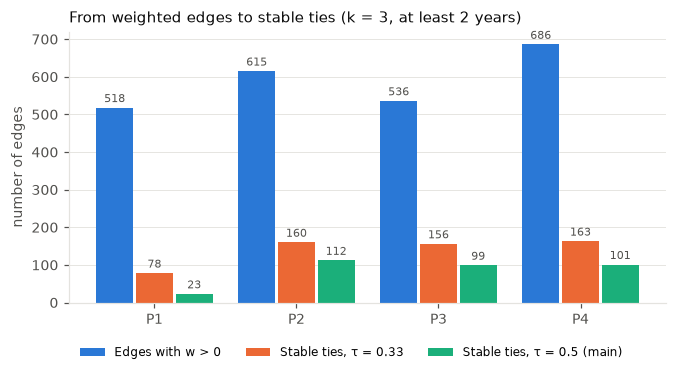

In [39]:
# edges with w > 0 vs stable ties, per period
main_sens = sensitivity[(sensitivity["k"] == 3) & (sensitivity["min_years"] == 2)]
bars = {
    "Edges with w > 0": [(main_results[p][0] > 0).values.sum() for p in PERIODS],
    "Stable ties, τ = 0.33": [main_sens[(main_sens["period"] == p) & (main_sens["tau"] == 0.33)]["stable_ties"].item() for p in PERIODS],
    "Stable ties, τ = 0.5 (main)": [main_sens[(main_sens["period"] == p) & (main_sens["tau"] == 0.5)]["stable_ties"].item() for p in PERIODS],
}
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.26
for j, (label, values) in enumerate(bars.items()):
    xs = [i + (j - 1) * (width + 0.02) for i in range(len(PERIODS))]
    ax.bar(xs, values, width=width, color=SERIES[j], label=label)
    for x, v in zip(xs, values):
        ax.text(x, v + 8, str(v), ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(range(len(PERIODS)), PERIODS)
ax.set_ylabel("number of edges")
ax.set_title("From weighted edges to stable ties (k = 3, at least 2 years)", loc="left", color=INK, fontsize=10)
ax.legend(loc="upper left", ncols=3, fontsize=8, bbox_to_anchor=(0, -0.12))
plt.show()

The stable ties are a small part of the weighted edges: with τ = 0.5, from 4% of the edges in P1 (23 of 518) to 18% in P2 and P3. With τ = 0.33 the share rises to between 15% (P1) and 29% (P3). P1 keeps by far the fewest stable ties, although it has the most finals.

### 8.2. Weights of the Edges

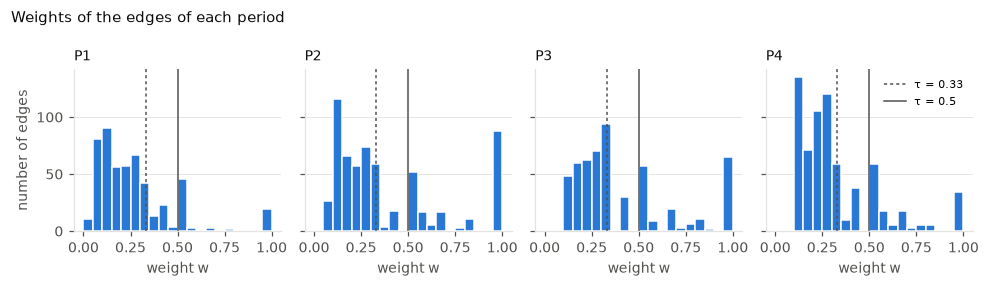

In [40]:
# distribution of the weights w > 0, with the two thresholds
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6), sharey=True)
for ax, p in zip(axes, PERIODS):
    adj = main_results[p][0]
    w = adj.values[(adj.values > 0) & ~np.eye(len(adj), dtype=bool)]
    ax.hist(w, bins=np.arange(0, 1.05, 0.05), color=SERIES[0], edgecolor="white", linewidth=1)
    for tau, ls in [(0.33, (0, (2, 2))), (0.5, "-")]:
        ax.axvline(tau, color=INK2, lw=1, ls=ls)
    ax.set_title(p, loc="left", color=INK, fontsize=9)
    ax.set_xlabel("weight w")
axes[0].set_ylabel("number of edges")
axes[-1].legend(handles=[plt.Line2D([], [], color=INK2, lw=1, ls=(0, (2, 2)), label="τ = 0.33"),
                         plt.Line2D([], [], color=INK2, lw=1, label="τ = 0.5")], fontsize=7, loc="upper right")
fig.suptitle("Weights of the edges of each period", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

Most edges have a low weight: B was in A's top 3 in only a few of the possible years. Each period also has a peak at w = 1 (pairs that were always in the top 3), smallest in P1, where the pairs could vote for each other in up to 22 finals. The lines show the two thresholds; a stable tie also needs at least 2 years in the top 3, so a few edges to the right of the line are still not stable ties.

### 8.3. Choosing k and the Minimum Number of Years

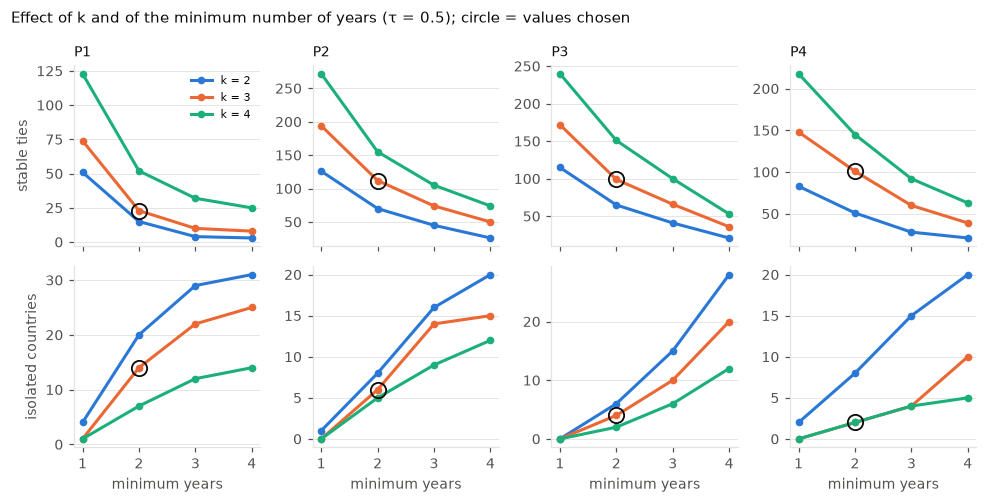

In [41]:
# effect of k and of the minimum number of years (τ = 0.5)
t05 = sensitivity[sensitivity["tau"] == 0.5]
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6), sharex=True)
for col, p in enumerate(PERIODS):
    for row, (measure, label) in enumerate([("stable_ties", "stable ties"), ("isolated", "isolated countries")]):
        ax = axes[row, col]
        for j, k in enumerate([2, 3, 4]):
            d = t05[(t05["period"] == p) & (t05["k"] == k)].sort_values("min_years")
            ax.plot(d["min_years"], d[measure], color=SERIES[j], lw=2, marker="o", ms=4, label=f"k = {k}")
        chosen = t05[(t05["period"] == p) & (t05["k"] == 3) & (t05["min_years"] == 2)][measure].item()
        ax.plot(2, chosen, marker="o", ms=10, mfc="none", mec=INK, mew=1.2)
        if row == 0:
            ax.set_title(p, loc="left", color=INK, fontsize=9)
        if col == 0:
            ax.set_ylabel(label)
        ax.set_xticks([1, 2, 3, 4])
for ax in axes[1]:
    ax.set_xlabel("minimum years")
axes[0, 0].legend(fontsize=7, loc="upper right")
fig.suptitle("Effect of k and of the minimum number of years (τ = 0.5); circle = values chosen",
             x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

Requiring more years removes stable ties and isolates more countries, in every period and for every k; a larger k does the opposite. The circle marks the values chosen (k = 3, 2 years): the last point before P1 loses most of its network, since with 3 years its isolated countries go from 14 to 22.

### 8.4. P4 by Voting Channel

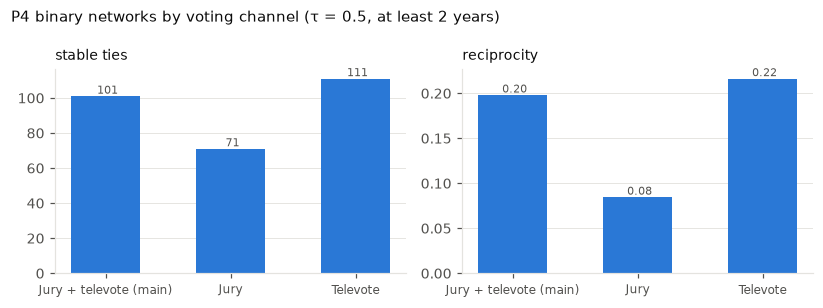

In [42]:
# P4: main network vs jury and televote networks
p4_binary = {"Jury + televote (main)": binarize_network(main_results["P4"][0], main_results["P4"][3], tau=0.5, min_years=2),
             "Jury": channel_results["jury"][1],
             "Televote": channel_results["televote"][1]}
graphs_p4 = {name: nx.from_pandas_adjacency(b, create_using=nx.DiGraph) for name, b in p4_binary.items()}
measures = {"stable ties": [G.number_of_edges() for G in graphs_p4.values()],
            "reciprocity": [nx.reciprocity(G) for G in graphs_p4.values()]}
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8))
for ax, (name, values) in zip(axes, measures.items()):
    ax.bar(range(3), values, width=0.55, color=SERIES[0])
    for i, v in enumerate(values):
        ax.text(i, v, f" {v:.2f}" if name == "reciprocity" else f" {v}", ha="center", va="bottom", fontsize=7, color=INK2)
    ax.set_xticks(range(3), list(graphs_p4), fontsize=8)
    ax.set_title(name, loc="left", color=INK, fontsize=9)
fig.suptitle("P4 binary networks by voting channel (τ = 0.5, at least 2 years)", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()

The jury network has fewer stable ties than the televote network (71 vs 111) and far fewer of them are returned (reciprocity 0.08 vs 0.22). The main P4 network, which adds both sets of points, is close to the televote one. Notebook 04 analyses this difference.

## 9. Outputs

| Folder | Files | Used in |
|---|---|---|
| `data/processed/` | `{period}_adj_topk3.csv`, `{period}_edgelist_topk3.csv`, `{period}_adj_binary_t05.csv`, `{period}_cepii_*.csv`, `cepii_*_all.csv` | notebooks 03, 04 |
| `data/processed/robustness/` | k = 2 and k = 4, rank weights, τ = 0.33, unconstrained binary, P1a / P1b | notebook 03 |
| `data/processed/p4_channels/` | jury and televote networks of P4 | notebook 04 |

The LaTeX tables of the report are exported by `latex_tables.ipynb`.